In [2]:
from pathlib import Path
from PIL import Image
import pandas as pd

BASE_DIR = Path(
    "/home/abi/vison-model/"
    "Vision-Based Product Attribution and BOM Mapping"
)

IMAGES_DIR = BASE_DIR / "data/combined/images"
LABELS_DIR = BASE_DIR / "data/combined/labels"

CROPS_DIR = BASE_DIR / "data/combined/crops"
CROPS_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = {
    0: "Bearing",
    1: "Bolt",
    2: "Gear",
    3: "Nut"
}

print("Images directory exists:", IMAGES_DIR.exists())
print("Labels directory exists:", LABELS_DIR.exists())
print("Images directory:", IMAGES_DIR)
print("Labels directory:", LABELS_DIR)
print("Crops directory:", CROPS_DIR)

Images directory exists: True
Labels directory exists: True
Images directory: /home/abi/vison-model/Vision-Based Product Attribution and BOM Mapping/data/combined/images
Labels directory: /home/abi/vison-model/Vision-Based Product Attribution and BOM Mapping/data/combined/labels
Crops directory: /home/abi/vison-model/Vision-Based Product Attribution and BOM Mapping/data/combined/crops


In [3]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = sorted(
    p for p in IMAGES_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

missing_labels = [
    p.name for p in image_paths
    if not (LABELS_DIR / f"{p.stem}.txt").exists()
]

print("Total images:", len(image_paths))
print("Matching labels:", len(image_paths) - len(missing_labels))
print("Missing labels:", len(missing_labels))

if missing_labels:
    print("\nExamples of missing labels:", missing_labels[:10])

Total images: 2131
Matching labels: 2131
Missing labels: 0


In [10]:
# Find the first image that has a corresponding label
sample_image = next(
    p for p in image_paths
    if (LABELS_DIR / f"{p.stem}.txt").exists()
)

sample_label = LABELS_DIR / f"{sample_image.stem}.txt"

print("Sample image:", sample_image.name)
print("Label file:", sample_label.name)
print("\nLabel contents:\n")

print(sample_label.read_text())

Sample image: 239_jpg.rf.a8e5954b06053030346dd3864d2e63cf.jpg
Label file: 239_jpg.rf.a8e5954b06053030346dd3864d2e63cf.txt

Label contents:

1 0.42578125 0.41484375 0.08203125 0.24296875
1 0.62890625 0.40390625 0.08359375 0.25
3 0.74375 0.32421875 0.08125 0.1203125
3 0.76171875 0.5109375 0.08359375 0.11796875
3 0.54296875 0.5625 0.08359375 0.1203125
3 0.64609375 0.76171875 0.08828125 0.1203125
1 0.4359375 0.6984375 0.15859375 0.2140625


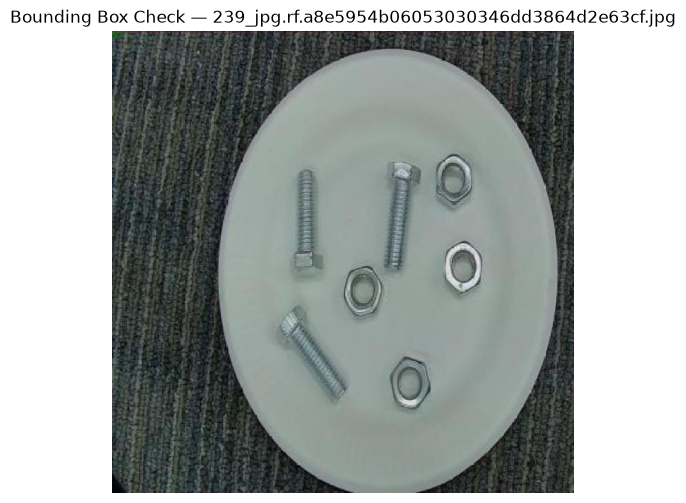

Detected class: Bolt
Bounding box: (0.384765625, 0.293359375, 0.466796875, 0.536328125)


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

image = Image.open(sample_image).convert("RGB")
width, height = image.size

line = sample_label.read_text().strip().splitlines()[0]
class_id, xc, yc, bw, bh = map(float, line.split())

x1 = int((xc - bw / 2) * )
y1 = int((yc - bh / 2) * height)
x2 = int((xc + bw / 2) * width)
y2 = int((yc + bh / 2) * height)


draw = ImageDraw.Draw(image)
draw.rectangle((x1, y1, x2, y2), outline="green", width=2)

class_name = CLASS_NAMES.get(int(class_id), "Unknown")
draw.text((x1, max(0, y1 - 20)), class_name, fill="green")

plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.title(f"Bounding Box Check — {sample_image.name}")
plt.axis("off")
plt.show()

print(f"Detected class: {class_name}")
print(f"Bounding box: ({x1}, {y1}, {x2}, {y2})")

In [21]:
from PIL import Image
import pandas as pd

crop_records = []
crop_id = 0
skipped = 0

for image_path in image_paths:
    label_path = LABELS_DIR / f"{image_path.stem}.txt"

    if not label_path.exists():
        skipped += 1
        continue

    with Image.open(image_path) as img:
        img = img.convert("RGB")
        width, height = img.size

        for line_no, line in enumerate(
            label_path.read_text().strip().splitlines(), start=1
        ):
            if not line.strip():
                continue

            values = line.split()
            if len(values) != 5:
                skipped += 1
                continue

            class_id, xc, yc, bw, bh = map(float, values)

            if int(class_id) not in CLASS_NAMES:
                skipped += 1
                continue

            x1 = max(0, int((xc - bw / 2) * width))
            y1 = max(0, int((yc - bh / 2) * height))
            x2 = min(width, int((xc + bw / 2) * width))
            y2 = min(height, int((yc + bh / 2) * height))

            if x2 <= x1 or y2 <= y1:
                skipped += 1
                continue

            # Add 5% padding around the component
            pad_x = int((x2 - x1) * 0.05)
            pad_y = int((y2 - y1) * 0.05)

            x1 = max(0, x1 - pad_x)
            y1 = max(0, y1 - pad_y)
            x2 = min(width, x2 + pad_x)
            y2 = min(height, y2 + pad_y)

            crop = img.crop((x1, y1, x2, y2))

            if crop.width < 32 or crop.height < 32:
                skipped += 1
                continue

            class_name = CLASS_NAMES[int(class_id)]
            class_dir = CROPS_DIR / class_name.lower()
            class_dir.mkdir(parents=True, exist_ok=True)

            crop_id += 1
            crop_name = f"CROP-{crop_id:06d}.jpg"
            crop_path = class_dir / crop_name

            crop.save(crop_path, quality=95)

            crop_records.append({
                "crop_id": crop_name.replace(".jpg", ""),
                "class_id": int(class_id),
                "class_name": class_name,
                "source_image": image_path.name,
                "label_line": line_no,
                "x1": x1,
                "y1": y1,
                "x2": x2,
                "y2": y2,
                "crop_width": crop.width,
                "crop_height": crop.height,
                "crop_path": str(crop_path),
                "product_id": None,
                "sku": None
            })

metadata = pd.DataFrame(crop_records)

metadata_path = BASE_DIR / "data/combined/crop_metadata.csv"
metadata.to_csv(metadata_path, index=False)

print("Images processed:", len(image_paths))
print("Component crops created:", len(metadata))
print("Skipped annotations:", skipped)
print("\nCrops by class:")
print(metadata["class_name"].value_counts())
print("\nMetadata saved to:", metadata_path)

Images processed: 2131
Component crops created: 10688
Skipped annotations: 406

Crops by class:
class_name
Nut        2977
Gear       2834
Bolt       2676
Bearing    2201
Name: count, dtype: int64

Metadata saved to: /home/abi/vison-model/Vision-Based Product Attribution and BOM Mapping/data/combined/crop_metadata.csv


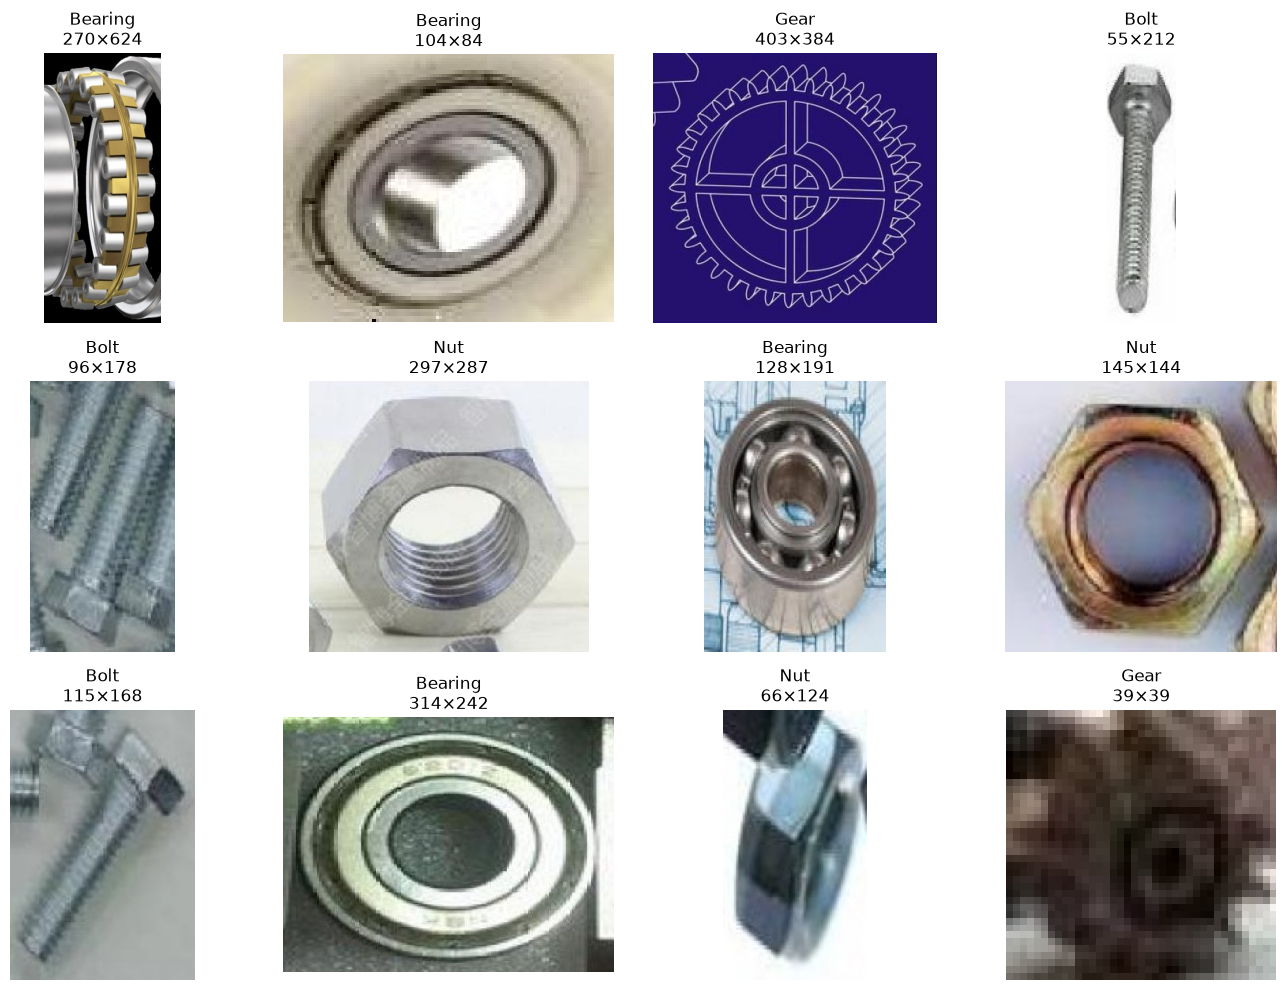

In [22]:
import matplotlib.pyplot as plt
import random

sample_crops = metadata.sample(
    n=min(12, len(metadata)),
    random_state=42
)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for ax, (_, row) in zip(axes.flat, sample_crops.iterrows()):
    img = Image.open(row["crop_path"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(
        f'{row["class_name"]}\n{row["crop_width"]}×{row["crop_height"]}'
    )
    ax.axis("off")

plt.tight_layout()
plt.show()